# 03 · Supervisé : Random Forest vs MLP, explications SHAP

**Date :** 3 novembre 2026 (test connu ajouté le 4 novembre 2026)

**Ce qui est fait :**
1. Random Forest multi-classe (benign + 7 attaques connues) : petite grille de réglages, choisie sur val (macro-F1).
2. MLP (sklearn) : 3 tailles de réseau, entraînées époque par époque, meilleure époque choisie sur val.
3. Comparaison RF vs MLP sur val (scores un peu optimistes, car la val a servi à choisir).
4. **Mesure finale sur test_connu, une seule fois** : métriques par classe sur des flux jamais utilisés pour choisir un réglage.
5. Sur test_inconnu (jeu + ven, attaques **jamais vues**) : part de chaque attaque signalée comme « attaque » et fausses alertes sur le benign.
6. Comparaison avec les chiffres de l'ancien découpage 80/20.
7. SHAP (TreeExplainer) sur le RF : caractéristiques les plus utilisées, puis explication d'une alerte.

**Pourquoi :** c'est la première comparaison demandée (RF vs MLP). Le RF retenu fournira l'étiquette « attaque connue » et ses explications SHAP aux agents (notebooks 05 et 07).

Rien n'est réglé sur test_connu ni sur test_inconnu (règle 7) : ils servent seulement à mesurer. Le critère de choix (macro-F1 sur val, 8 classes) a été fixé avant de calculer la moindre prédiction sur test_connu.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path.cwd().parent / "src"))
from isocrates.ml.data import LABEL, BENIGN, ROOT
from isocrates.ml.supervised import (load_sets, signed_log, fit_rf, fit_mlp, macro_f1, macro_f1_without,
                                     per_class_report, detection_by_class, save_model)

REPORTS = ROOT / "reports"
sns.set_theme(style="whitegrid")

sets, features = load_sets()

# X = caractéristiques (tableau numpy), y = étiquettes
X_train = sets["train"][features].to_numpy(np.float32)
X_val = sets["val"][features].to_numpy(np.float32)
X_connu = sets["test_connu"][features].to_numpy(np.float32)
X_inconnu = sets["test_inconnu"][features].to_numpy(np.float32)
y_train = sets["train"][LABEL].to_numpy()
y_val = sets["val"][LABEL].to_numpy()
y_connu = sets["test_connu"][LABEL].to_numpy()
y_inconnu = sets["test_inconnu"][LABEL].to_numpy()

known = sorted(set(y_train))   # les 8 classes connues du modèle
print(len(features), "caractéristiques")
print("Classes connues :", known)
print("Flux : train", len(y_train), "· val", len(y_val), "· test_connu", len(y_connu), "· test_inconnu", len(y_inconnu))

78 caractéristiques
Classes connues : ['benign', 'dos_goldeneye', 'dos_hulk', 'dos_slowhttptest', 'dos_slowloris', 'ftp_patator', 'heartbleed', 'ssh_patator']
Flux : train 827434 · val 177308 · test_connu 177313 · test_inconnu 655443


## 1. Random Forest : réglage sur val

100 arbres. On essaie 6 combinaisons : profondeur maximale (10, 20, illimitée) × poids de classe (aucun, `balanced_subsample`). Critère : **macro-F1** sur val (moyenne des F1 des 8 classes, chacune compte autant).

La colonne « sans heartbleed » est là pour information : heartbleed n'a que 2 flux en val, donc une seule erreur change beaucoup son F1. Elle ne sert pas au choix. En cas d'égalité, on garde la première ligne.

In [2]:
rf_results = []
rf_models = []

for depth in [10, 20, None]:
    for weight in [None, "balanced_subsample"]:
        model, duration = fit_rf(X_train, y_train, max_depth=depth, class_weight=weight)
        predictions = model.predict(X_val)
        score = macro_f1(y_val, predictions)
        rf_results.append({
            "max_depth": "illimitée" if depth is None else depth,
            "class_weight": "aucun" if weight is None else weight,
            "macro-F1 val": round(score, 4),
            "sans heartbleed": round(macro_f1_without(y_val, predictions, known, "heartbleed"), 4),
            "temps (s)": round(duration),
        })
        rf_models.append(model)

rf_table = pd.DataFrame(rf_results)
best = rf_table["macro-F1 val"].idxmax()   # numéro de la meilleure ligne
rf = rf_models[best]
print("Retenu :", rf_table.loc[best].to_dict())
rf_table

Retenu : {'max_depth': 20, 'class_weight': 'aucun', 'macro-F1 val': 0.9757, 'sans heartbleed': 0.9722, 'temps (s)': 24}


,max_depth,class_weight,macro-F1 val,sans heartbleed,temps (s)
0,10,aucun,0.9739,0.9702,22
1,10,balanced_subsample,0.9718,0.9677,28
2,20,aucun,0.9757,0.9722,24
3,20,balanced_subsample,0.9722,0.9682,30
4,illimitée,aucun,0.9757,0.9722,25
5,illimitée,balanced_subsample,0.9736,0.9698,29


## 2. MLP : réglage sur val

Un réseau de neurones a besoin d'entrées à la même échelle :
1. `sign(x)·log(1+|x|)` écrase les très grandes valeurs (débits, durées en µs) ;
2. `StandardScaler` (moyenne 0, écart-type 1), **ajusté sur train seulement**.

3 tailles de couches cachées, 20 époques chacune (lots de 1 024 flux, Adam). Poids des classes en racine de « balanced ». À chaque époque on calcule le macro-F1 sur **notre** val temporelle et on garde la meilleure époque.

In [3]:
scaler = StandardScaler()
scaler.fit(signed_log(X_train))          # moyenne et écart-type calculés sur train uniquement
Z_train = scaler.transform(signed_log(X_train))
Z_val = scaler.transform(signed_log(X_val))
Z_connu = scaler.transform(signed_log(X_connu))
Z_inconnu = scaler.transform(signed_log(X_inconnu))

mlp_results = []
mlp_models = []
histories = {}

for hidden in [(64, 32), (128, 64), (256, 128)]:
    model, history, best_epoch, duration = fit_mlp(Z_train, y_train, Z_val, y_val, hidden=hidden, epochs=20)
    histories[str(hidden)] = history
    mlp_results.append({
        "couches": str(hidden),
        "meilleure époque": best_epoch,
        "macro-F1 val": round(history["macro-F1 val"].max(), 4),
        "sans heartbleed": round(macro_f1_without(y_val, model.predict(Z_val), known, "heartbleed"), 4),
        "temps (s)": round(duration),
    })
    mlp_models.append(model)

mlp_table = pd.DataFrame(mlp_results)
best = mlp_table["macro-F1 val"].idxmax()
mlp = mlp_models[best]
print("Retenu :", mlp_table.loc[best].to_dict())
mlp_table

Retenu : {'couches': '(128, 64)', 'meilleure époque': 9, 'macro-F1 val': 0.9775, 'sans heartbleed': 0.9743, 'temps (s)': 114}


,couches,meilleure époque,macro-F1 val,sans heartbleed,temps (s)
0,"(64, 32)",6,0.9364,0.9749,91
1,"(128, 64)",9,0.9775,0.9743,114
2,"(256, 128)",10,0.9382,0.9770,231


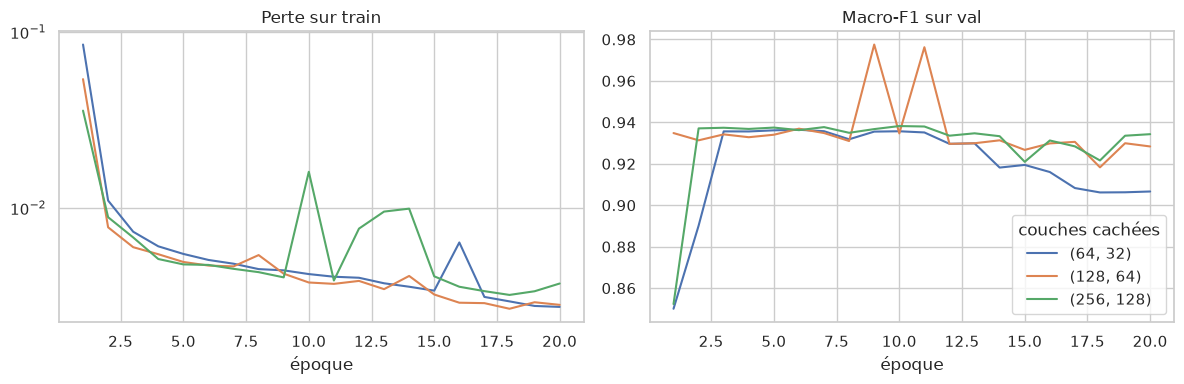

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in histories.items():
    axes[0].plot(history["époque"], history["perte train"], label=name)
    axes[1].plot(history["époque"], history["macro-F1 val"], label=name)
axes[0].set_title("Perte sur train")
axes[0].set_xlabel("époque")
axes[0].set_yscale("log")
axes[1].set_title("Macro-F1 sur val")
axes[1].set_xlabel("époque")
axes[1].legend(title="couches cachées")
fig.tight_layout()
fig.savefig(REPORTS / "03_mlp_epoques.png", dpi=150)
plt.show()

## 3. Comparaison sur val (attaques connues)

Ces scores sont un peu optimistes : la val a servi à choisir les réglages.

In [5]:
rf_val = rf.predict(X_val)
mlp_val = mlp.predict(Z_val)
rf_report = per_class_report(y_val, rf_val, known)
mlp_report = per_class_report(y_val, mlp_val, known)
pd.concat({"RF": rf_report, "MLP": mlp_report}, axis=1)

RF                             MLP                \
                 précision rappel     F1    flux précision rappel     F1   
benign               0.999  1.000  0.999  149818     0.999  1.000  0.999   
dos_goldeneye        0.999  1.000  1.000    1015     0.999  0.986  0.993   
dos_hulk             1.000  1.000  1.000   23848     1.000  1.000  1.000   
dos_slowhttptest     0.996  0.719  0.835     730     0.967  0.767  0.856   
dos_slowloris        0.966  1.000  0.983     851     0.992  1.000  0.996   
ftp_patator          1.000  1.000  1.000     600     1.000  1.000  1.000   
heartbleed           1.000  1.000  1.000       2     1.000  1.000  1.000   
ssh_patator          0.978  1.000  0.989     444     0.955  1.000  0.977   

                          
                    flux  
benign            149818  
dos_goldeneye       1015  
dos_hulk           23848  
dos_slowhttptest     730  
dos_slowloris        851  
ftp_patator          600  
heartbleed             2  
ssh_patator          444

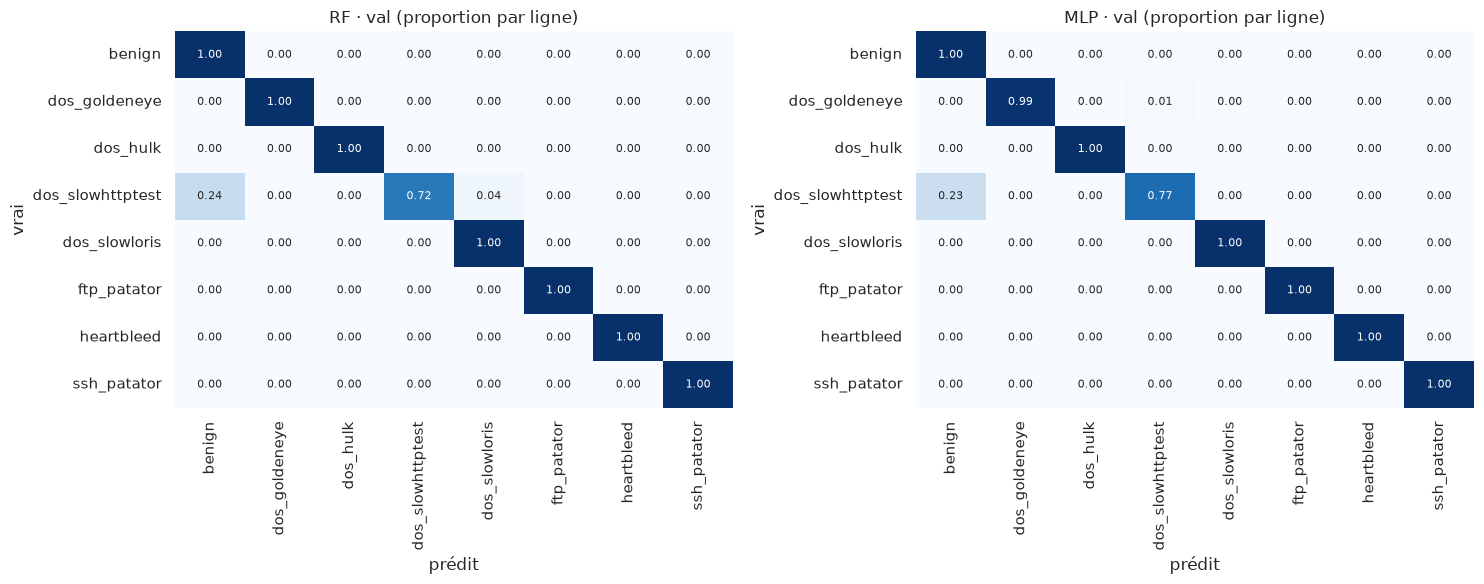

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, name, predictions in [(axes[0], "RF", rf_val), (axes[1], "MLP", mlp_val)]:
    # matrice de confusion en proportion de chaque ligne (chaque vraie classe)
    cm = pd.crosstab(pd.Series(y_val, name="vrai"), pd.Series(predictions, name="prédit"), normalize="index")
    cm = cm.reindex(index=known, columns=known, fill_value=0)
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax, annot_kws={"size": 8})
    ax.set_title(name + " · val (proportion par ligne)")
fig.tight_layout()
fig.savefig(REPORTS / "03_confusion_val.png", dpi=150)
plt.show()

## 4. Mesure finale sur test_connu (une seule fois)

Les réglages sont figés. On mesure les attaques connues sur les 15 % de flux les plus récents de chaque classe, jamais utilisés pour choisir quoi que ce soit.

**Heartbleed est exclu du macro-F1** : il n'a que 2 flux ici, donc son F1 ne vaut que 0, 0,67 ou 1. Sa ligne reste affichée dans le tableau, à titre indicatif.

**Limite :** test_connu vient du même jour que le train, juste après lui. C'est donc plus facile qu'une attaque rejouée un autre jour.

In [7]:
rf_connu = rf.predict(X_connu)
mlp_connu = mlp.predict(Z_connu)

rf_connu_report = per_class_report(y_connu, rf_connu, known)
mlp_connu_report = per_class_report(y_connu, mlp_connu, known)

print("Macro-F1 test_connu sans heartbleed : RF =", round(macro_f1_without(y_connu, rf_connu, known, "heartbleed"), 4),
      "· MLP =", round(macro_f1_without(y_connu, mlp_connu, known, "heartbleed"), 4))
pd.concat({"RF": rf_connu_report, "MLP": mlp_connu_report}, axis=1)

Macro-F1 test_connu sans heartbleed : RF = 0.9574 · MLP = 0.9334


RF                             MLP                \
                 précision rappel     F1    flux précision rappel     F1   
benign               0.999  1.000  0.999  149820     1.000  1.000  1.000   
dos_goldeneye        1.000  0.994  0.997    1015     1.000  0.991  0.996   
dos_hulk             1.000  0.994  0.997   23849     1.000  0.994  0.997   
dos_slowhttptest     0.780  0.996  0.875     730     0.621  0.992  0.764   
dos_slowloris        0.995  0.759  0.862     852     0.982  0.655  0.786   
ftp_patator          1.000  1.000  1.000     601     1.000  1.000  1.000   
heartbleed           1.000  0.500  0.667       2     1.000  1.000  1.000   
ssh_patator          1.000  0.946  0.972     444     0.995  0.986  0.991   

                          
                    flux  
benign            149820  
dos_goldeneye       1015  
dos_hulk           23849  
dos_slowhttptest     730  
dos_slowloris        852  
ftp_patator          601  
heartbleed             2  
ssh_patator          444

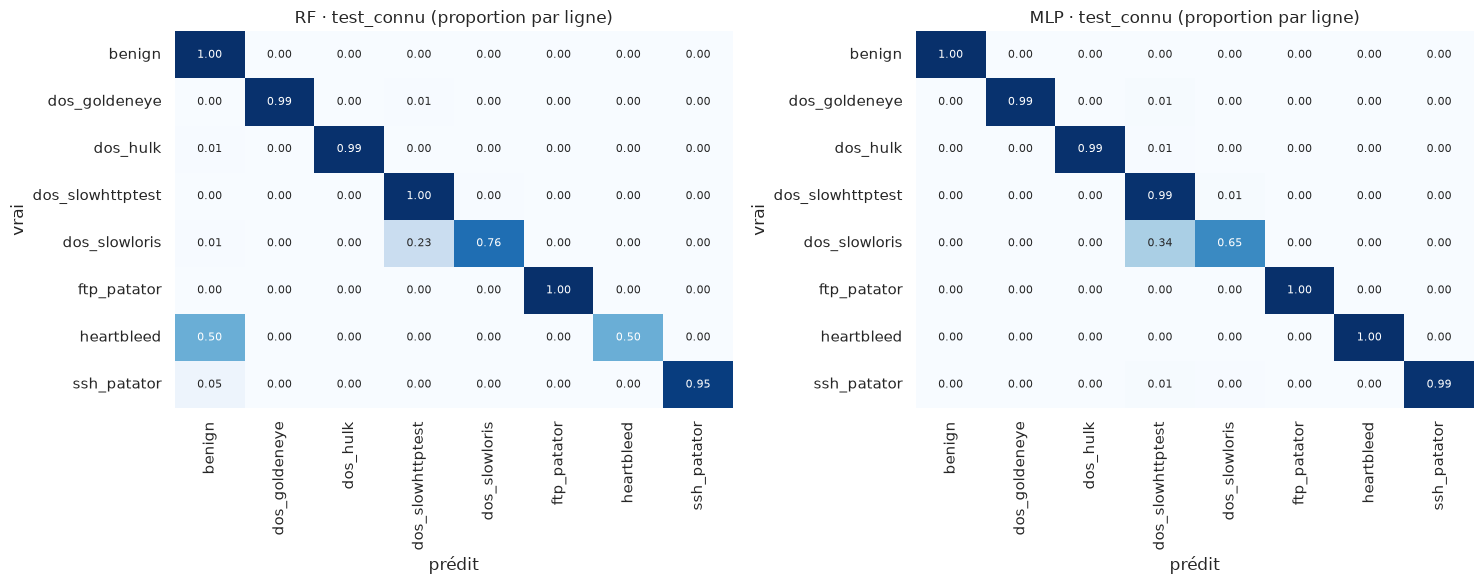

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, name, predictions in [(axes[0], "RF", rf_connu), (axes[1], "MLP", mlp_connu)]:
    cm = pd.crosstab(pd.Series(y_connu, name="vrai"), pd.Series(predictions, name="prédit"), normalize="index")
    cm = cm.reindex(index=known, columns=known, fill_value=0)
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax, annot_kws={"size": 8})
    ax.set_title(name + " · test_connu (proportion par ligne)")
fig.tight_layout()
fig.savefig(REPORTS / "03_confusion_test_connu.png", dpi=150)
plt.show()

## 5. test_inconnu : attaques jamais vues

Le RF et le MLP ne connaissent aucune de ces attaques par leur nom. On mesure donc la **détection** : part des flux de chaque classe prédits comme n'importe quelle attaque (≠ benign). Pour benign, c'est le taux de fausses alertes.

In [9]:
rf_inconnu = rf.predict(X_inconnu)
mlp_inconnu = mlp.predict(Z_inconnu)

detection = pd.DataFrame({
    "RF": detection_by_class(y_inconnu, rf_inconnu),
    "MLP": detection_by_class(y_inconnu, mlp_inconnu),
})
detection["flux"] = pd.Series(y_inconnu).value_counts()
detection.round(3)

,RF,MLP,flux
benign,0.000,0.000,396886
bot,0.000,0.000,735
ddos,0.977,0.999,95683
portscan,0.000,0.000,160106
webattack_bruteforce,0.109,0.943,1360
webattack_sql_injection,0.083,0.000,12
webattack_xss,0.113,0.997,661


In [10]:
# Sous quelle étiquette connue le RF range-t-il chaque attaque inconnue ? (proportion par ligne)
table = pd.crosstab(pd.Series(y_inconnu, name="vrai (test_inconnu)"), pd.Series(rf_inconnu, name="prédit par le RF"),
                    normalize="index").round(3)
table

prédit par le RF,benign,dos_goldeneye,dos_hulk,dos_slowhttptest,dos_slowloris
vrai (test_inconnu),,,,,
benign,1.000,0.000,0.000,0.0,0.000
bot,1.000,0.000,0.000,0.0,0.000
ddos,0.023,0.000,0.977,0.0,0.000
portscan,1.000,0.000,0.000,0.0,0.000
webattack_bruteforce,0.891,0.000,0.098,0.0,0.011
webattack_sql_injection,0.917,0.083,0.000,0.0,0.000
webattack_xss,0.887,0.002,0.103,0.0,0.009


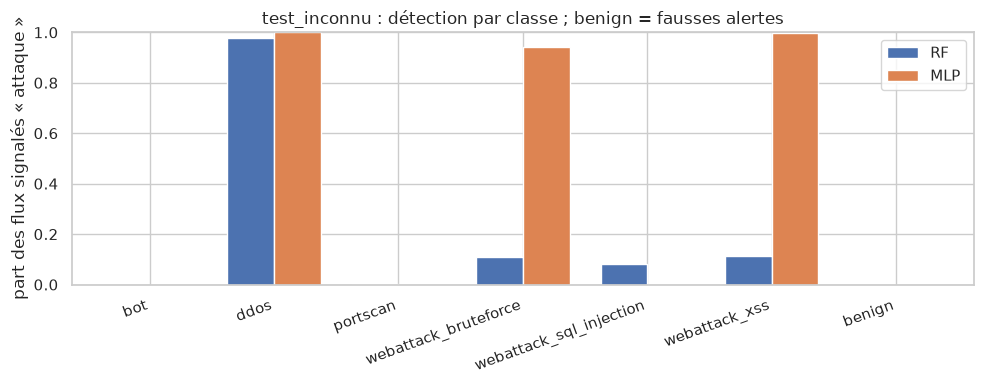

In [11]:
test_attacks = [name for name in detection.index if name != BENIGN]

fig, ax = plt.subplots(figsize=(10, 4))
detection.loc[test_attacks + [BENIGN], ["RF", "MLP"]].plot.bar(ax=ax, width=0.75, color=["#4C72B0", "#DD8452"])
ax.set_ylabel("part des flux signalés « attaque »")
ax.set_ylim(0, 1)
ax.set_title("test_inconnu : détection par classe ; benign = fausses alertes")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
fig.tight_layout()
fig.savefig(REPORTS / "03_detection_test.png", dpi=150)
plt.show()

In [12]:
# Temps de prédiction pour 100 000 flux
start = time.perf_counter()
rf.predict(X_inconnu[:100_000])
rf_time = time.perf_counter() - start

start = time.perf_counter()
mlp.predict(scaler.transform(signed_log(X_inconnu[:100_000])))
mlp_time = time.perf_counter() - start

summary = pd.DataFrame({
    "macro-F1 val": [rf_table["macro-F1 val"].max(), mlp_table["macro-F1 val"].max()],
    "prédiction 100 000 flux (s)": [round(rf_time, 2), round(mlp_time, 2)],
    "fausses alertes test_inconnu (benign)": [detection.loc[BENIGN, "RF"], detection.loc[BENIGN, "MLP"]],
}, index=["RF", "MLP"])
summary

,macro-F1 val,prédiction 100 000 flux (s),fausses alertes test_inconnu (benign)
RF,0.9757,0.11,0.000025
MLP,0.9775,0.14,0.000096


## 6. Comparaison avec l'ancien découpage 80/20

Anciens chiffres : exécution du 3 novembre (commit 6e248de), recopiés ici à la main. Attention : l'ancienne val (les 20 % les plus récents) n'est pas la même que la nouvelle (de 70 à 85 %), et le modèle s'entraîne maintenant sur 70 % au lieu de 80 %. La comparaison sur val est donc indicative.

In [13]:
# F1 par classe avec l'ancien découpage (ancienne val)
old_f1 = pd.DataFrame({
    "RF ancien (val)": {"benign": 1.000, "dos_goldeneye": 0.997, "dos_hulk": 1.000, "dos_slowhttptest": 0.896,
                        "dos_slowloris": 0.884, "ftp_patator": 1.000, "heartbleed": 1.000, "ssh_patator": 0.967},
    "MLP ancien (val)": {"benign": 1.000, "dos_goldeneye": 0.996, "dos_hulk": 1.000, "dos_slowhttptest": 0.870,
                         "dos_slowloris": 0.861, "ftp_patator": 1.000, "heartbleed": 1.000, "ssh_patator": 0.983},
})
new_f1 = pd.DataFrame({
    "RF nouveau (val)": per_class_report(y_val, rf_val, known)["F1"],
    "RF test_connu": rf_connu_report["F1"],
    "MLP nouveau (val)": per_class_report(y_val, mlp_val, known)["F1"],
    "MLP test_connu": mlp_connu_report["F1"],
})
pd.concat([old_f1, new_f1], axis=1)

,RF ancien (val),MLP ancien (val),RF nouveau (val),RF test_connu,MLP nouveau (val),MLP test_connu
benign,1.000,1.000,0.999,0.999,0.999,1.000
dos_goldeneye,0.997,0.996,1.000,0.997,0.993,0.996
dos_hulk,1.000,1.000,1.000,0.997,1.000,0.997
dos_slowhttptest,0.896,0.870,0.835,0.875,0.856,0.764
dos_slowloris,0.884,0.861,0.983,0.862,0.996,0.786
ftp_patator,1.000,1.000,1.000,1.000,1.000,1.000
heartbleed,1.000,1.000,1.000,0.667,1.000,1.000
ssh_patator,0.967,0.983,0.989,0.972,0.977,0.991


In [14]:
# Détection sur test_inconnu : mêmes flux qu'avant, seuls les modèles ont changé
old_detection = pd.DataFrame({
    "RF ancien": {"benign": 0.000003, "bot": 0.000, "ddos": 0.986, "portscan": 0.000, "webattack_bruteforce": 0.000,
                  "webattack_sql_injection": 0.000, "webattack_xss": 0.002},
    "MLP ancien": {"benign": 0.000116, "bot": 0.000, "ddos": 1.000, "portscan": 0.000, "webattack_bruteforce": 0.940,
                   "webattack_sql_injection": 0.167, "webattack_xss": 0.997},
})
new_detection = detection[["RF", "MLP"]].rename(columns={"RF": "RF nouveau", "MLP": "MLP nouveau"})
pd.concat([old_detection, new_detection], axis=1).round(4)

,RF ancien,MLP ancien,RF nouveau,MLP nouveau
benign,0.000,0.0001,0.0000,0.0001
bot,0.000,0.0000,0.0000,0.0000
ddos,0.986,1.0000,0.9773,0.9994
portscan,0.000,0.0000,0.0003,0.0000
webattack_bruteforce,0.000,0.9400,0.1088,0.9434
webattack_sql_injection,0.000,0.1670,0.0833,0.0000
webattack_xss,0.002,0.9970,0.1135,0.9970


## 7. SHAP : pourquoi le RF décide

TreeExplainer calcule, pour chaque flux, la **contribution** de chaque caractéristique au score de chaque classe : une valeur positive pousse vers la classe, une valeur négative éloigne.

Échantillon de val : au plus 100 flux par classe (graine fixe).

In [15]:
# Échantillon : au plus 100 flux de val par classe
rng = np.random.default_rng(0)
sample_index = []
for name in known:
    positions = np.flatnonzero(y_val == name)          # numéros des flux de cette classe
    n = min(len(positions), 100)
    sample_index.extend(rng.choice(positions, size=n, replace=False))
sample_index = np.array(sample_index)
X_sample = X_val[sample_index]
y_sample = y_val[sample_index]
print("Flux par classe dans l'échantillon :", pd.Series(y_sample).value_counts().to_dict())

explainer = shap.TreeExplainer(rf)
start = time.perf_counter()
shap_values = explainer(X_sample)
shap_values.feature_names = features
print("SHAP calculé en", round(time.perf_counter() - start), "s ; forme", shap_values.values.shape, "= (flux, caractéristiques, classes)")

Flux par classe dans l'échantillon : {'benign': 100, 'dos_goldeneye': 100, 'dos_hulk': 100, 'dos_slowhttptest': 100, 'dos_slowloris': 100, 'ftp_patator': 100, 'ssh_patator': 100, 'heartbleed': 2}


SHAP calculé en 9 s ; forme (702, 78, 8) = (flux, caractéristiques, classes)


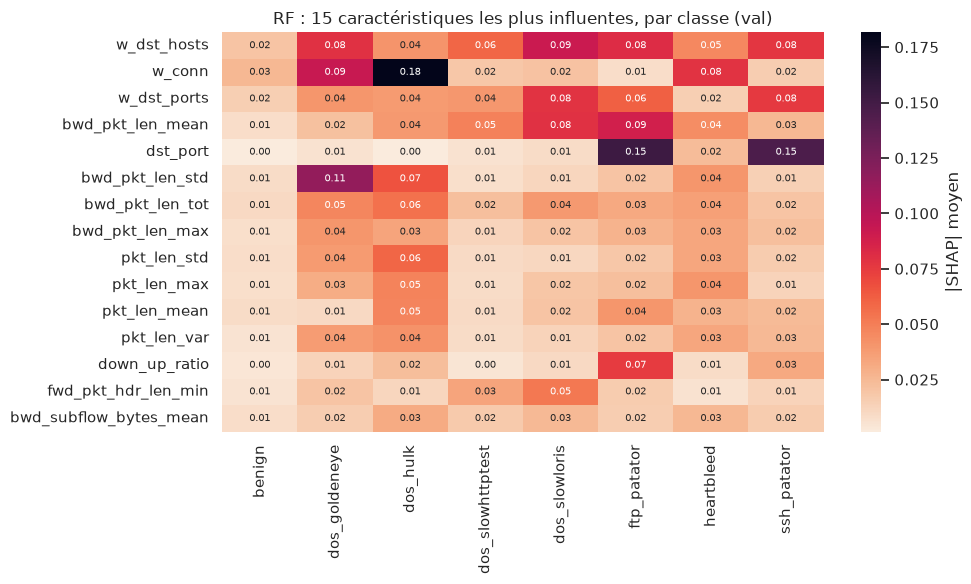

In [16]:
# Importance de chaque caractéristique pour chaque classe :
# moyenne de |SHAP| sur les flux de cette classe, pour le score de cette classe
classes = list(rf.classes_)
importance = pd.DataFrame(index=features)
for k, name in enumerate(classes):
    rows = y_sample == name
    importance[name] = np.abs(shap_values.values[rows, :, k]).mean(axis=0)

top15 = importance.sum(axis=1).sort_values(ascending=False).head(15).index

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(importance.loc[top15], cmap="rocket_r", annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax,
            cbar_kws={"label": "|SHAP| moyen"})
ax.set_title("RF : 15 caractéristiques les plus influentes, par classe (val)")
fig.tight_layout()
fig.savefig(REPORTS / "03_shap_global.png", dpi=150)
plt.show()

### Explication d'une alerte

Un flux de **portscan** de test_inconnu (attaque inconnue du RF) qu'il signale comme attaque : quelle étiquette connue lui donne-t-il, et pourquoi ? C'est ce type d'explication que recevront les agents.

In [17]:
flagged = np.flatnonzero((y_inconnu == "portscan") & (rf_inconnu != BENIGN))
print(len(flagged), "flux de portscan sur", (y_inconnu == "portscan").sum(), "sont signalés par le RF")

i = rng.choice(flagged)                       # on en choisit un au hasard (graine fixe)
predicted = rf_inconnu[i]
k = classes.index(predicted)
probability = rf.predict_proba(X_inconnu[[i]])[0, k]
print("Flux test_inconnu n°", i, ": vrai = portscan, prédit =", predicted, "avec une probabilité de", round(probability, 2))

one = explainer(X_inconnu[[i]])
one.feature_names = features

# Les 8 caractéristiques qui ont le plus pesé
contributions = pd.DataFrame({"valeur": X_inconnu[i], "SHAP": one.values[0, :, k]}, index=features)
contributions["|SHAP|"] = contributions["SHAP"].abs()
contributions.sort_values("|SHAP|", ascending=False).head(8).drop(columns="|SHAP|").round(3)

55 flux de portscan sur 160106 sont signalés par le RF
Flux test_inconnu n° 477153 : vrai = portscan, prédit = dos_hulk avec une probabilité de 0.51


,valeur,SHAP
w_conn,5.040000e+03,0.192
bwd_pkt_len_tot,1.159500e+04,0.056
w_dst_ports,9.990000e+02,-0.055
pkt_len_mean,1.290333e+03,0.047
bwd_iat_tot,6.004096e+06,-0.043
bwd_iat_max,6.003415e+06,-0.039
pkt_len_max,4.344000e+03,0.033
bwd_pkt_len_std,1.754831e+03,0.032


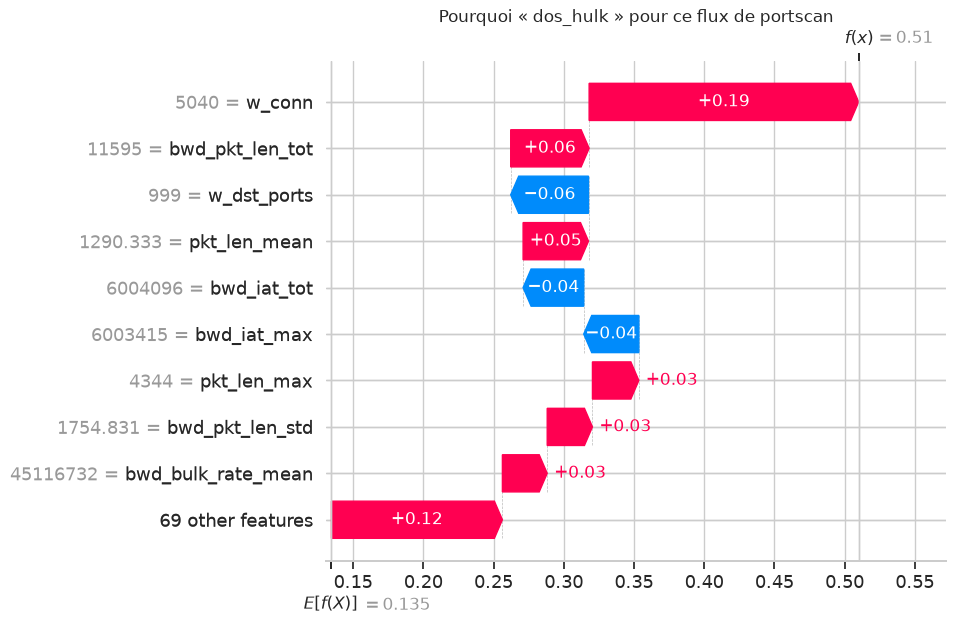

In [18]:
shap.plots.waterfall(one[0, :, k], max_display=10, show=False)
plt.title("Pourquoi « " + predicted + " » pour ce flux de portscan")
plt.gcf().savefig(REPORTS / "03_shap_exemple.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Sauvegarde des modèles

Dans `models/` (exclu de Git) : le RF retenu, et le MLP retenu avec son scaler (il faut le même scaler pour prédire).

In [19]:
save_model(rf, "rf")
save_model({"scaler": scaler, "mlp": mlp}, "mlp")
for path in sorted((ROOT / "models").glob("*.joblib")):
    print(path.name, ":", round(path.stat().st_size / 1e6, 1), "Mo")

mlp.joblib : 0.3 Mo
rf.joblib : 1.2 Mo


## Observations

1. **Réglages retenus sur val.** RF : profondeur 20, sans poids de classe (macro-F1 val **0,9757**). MLP : couches (128, 64), époque 9 (macro-F1 val **0,9775**). Le critère a été fixé avant de calculer la moindre prédiction sur test_connu, et rien n'a été changé après.
2. **Mesure finale sur test_connu, sans heartbleed : RF 0,9574, MLP 0,9334.** Les scores de val, sans heartbleed, étaient de 0,9722 et 0,9743 : ils étaient donc bien optimistes (écart de 0,015 pour le RF, de 0,041 pour le MLP). Le classement s'inverse : le MLP était très légèrement devant sur val, le RF est devant sur test_connu.
3. **Le test connu révèle une faiblesse cachée par la val : dos_slowloris.** Son F1 passe de 0,983 (val) à 0,862 (test_connu) pour le RF, de 0,996 à 0,786 pour le MLP. Sur test_connu, 199 flux slowloris sur 852 sont pris pour dos_slowhttptest par le RF, 289 par le MLP. Ces flux restent signalés comme attaques : seul le nom est faux. Le RF ne laisse passer que 6 slowloris comme benign, le MLP 3.
4. **Le comportement change au cours d'une même attaque.** Sur val, le problème était inverse : dos_slowhttptest a un rappel de 0,72 (RF), et 174 de ses 730 flux sont pris pour du benign. Sur test_connu, son rappel remonte à 0,996. Une même classe n'est donc pas également facile du début à la fin de l'attaque.
5. **Les autres classes connues restent très bonnes sur test_connu.** F1 de 0,997 pour goldeneye et hulk, 1,000 pour ftp_patator ; ssh_patator à 0,972 (RF) et 0,991 (MLP). Fausses alertes sur le benign de test_connu : 0 sur 149 820 pour le RF, 2 pour le MLP.
6. **Heartbleed décide du choix du MLP.** La taille (128, 64) l'emporte seulement parce qu'elle réussit les 2 flux heartbleed de val : sans heartbleed, elle est dernière (0,9743, contre 0,9770 pour (256, 128) et 0,9749 pour (64, 32)). L'écart reste très faible. Le choix du RF ne dépend pas de heartbleed. Sur test_connu, le RF rate 1 flux heartbleed sur 2, le MLP aucun : avec si peu de flux, cela ne prouve rien.
7. **test_inconnu : le MLP généralise toujours mieux.** Détection RF / MLP : ddos 97,7 % / 99,9 % ; webattack_xss 11,3 % / 99,7 % ; webattack_bruteforce 10,9 % / 94,3 % ; sql_injection 1 sur 12 / 0 sur 12. Portscan et bot restent presque invisibles (55 et 4 flux de portscan sur 160 106, aucun bot) : c'est le rôle du détecteur d'anomalies (notebook 04). Fausses alertes : 10 flux pour le RF, 38 pour le MLP, sur 396 886.
8. **Comparaison avec l'ancien découpage.** Le RF passe de la profondeur 10 à la profondeur 20, et détecte maintenant environ 11 % des attaques web (contre presque 0). Le résultat « le RF ne voit aucune attaque web » dépendait donc du réglage. Les F1 de l'ancienne val sur slowloris et slowhttptest (0,884 et 0,896 pour le RF) ressemblent à ceux de test_connu (0,862 et 0,875) : l'ancienne val couvrait les 20 % les plus récents, donc en partie les mêmes flux.
9. **SHAP.** Les caractéristiques de fenêtre restent parmi les plus utilisées (`w_conn` pour dos_hulk, `w_dst_hosts` pour presque toutes les classes), et `dst_port` domine pour ftp et ssh_patator. Exemple d'alerte : un flux de portscan appelé « dos_hulk » (probabilité 0,51), surtout à cause de son grand `w_conn`, alors que `w_dst_ports` = 999 tire dans l'autre sens. Pour une attaque inconnue, l'étiquette du RF n'est qu'un indice.
10. **Choix pour la suite.** Le RF reste dans le pipeline comme prévu dans l'architecture, parce que SHAP TreeExplainer l'explique exactement. Ce n'est **pas** parce qu'il est meilleur sur val (il ne l'est plus), et test_connu ne doit pas servir à choisir (règle 7).

**Limite à citer dans le rapport :** le test connu vient du même jour que l'entraînement et le suit immédiatement dans le temps, car LYCOS-IDS2017 ne rejoue aucune attaque un autre jour. Ses scores mesurent donc la suite d'une attaque déjà vue et sont plus faciles à obtenir que la détection d'une attaque rejouée un autre jour.